In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("bank_balance_sheet.csv", parse_dates=["month"])
df.head()

,bank,month,item,balance_bn
0,Bank_A,2019-01-31,Total_Assets,2000.88
1,Bank_A,2019-02-28,Total_Assets,1996.23
2,Bank_A,2019-03-31,Total_Assets,2020.20
3,Bank_A,2019-04-30,Total_Assets,2047.52
4,Bank_A,2019-05-31,Total_Assets,2027.84


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 864 entries, 0 to 863
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   bank        864 non-null    str           
 1   month       864 non-null    datetime64[us]
 2   item        864 non-null    str           
 3   balance_bn  864 non-null    float64       
dtypes: datetime64[us](1), float64(1), str(2)
memory usage: 27.1 KB


In [5]:
df.describe()

,month,balance_bn
count,864,864.000000
mean,2022-01-14 09:20:00,720.803970
min,2019-01-31 00:00:00,14.590000
25%,2020-07-23 06:00:00,135.195000
50%,2022-01-15 12:00:00,386.100000
75%,2023-07-07 18:00:00,1096.772500
max,2024-12-31 00:00:00,3184.030000
std,NaN,820.024783


In [6]:
df.groupby(["bank", "item"]).size()

bank    item        
Bank_A  Borrowings      72
        Deposits        72
        Loans           72
        Total_Assets    72
Bank_B  Borrowings      72
        Deposits        72
        Loans           72
        Total_Assets    72
Bank_C  Borrowings      72
        Deposits        72
        Loans           72
        Total_Assets    72
dtype: int64

In [7]:
wide = df.pivot_table(index="month", columns=["bank", "item"], values="balance_bn")

In [8]:
wide.head()

bank           Bank_A                                    Bank_B           \
item       Borrowings Deposits    Loans Total_Assets Borrowings Deposits   
month                                                                      
2019-01-31     202.23  1486.03  1187.77      2000.88      54.36   448.57   
2019-02-28     210.95  1489.39  1201.99      1996.23      53.64   443.87   
2019-03-31     210.60  1490.12  1212.11      2020.20      57.70   450.24   
2019-04-30     206.84  1497.17  1228.97      2047.52      58.62   450.49   
2019-05-31     206.07  1520.52  1232.32      2027.84      57.81   451.03   

bank                                Bank_C                               
item         Loans Total_Assets Borrowings Deposits  Loans Total_Assets  
month                                                                    
2019-01-31  359.09       597.40      15.16   112.18  90.06       151.30  
2019-02-28  362.98       600.49      15.38   113.99  90.34       153.72  
2019-03-31  369.15       602.88      14.60   112.33  92.64       154.33  
2019-04-30  367.83       607.23      14.59   111.49  93.13       155.71  
2019-05-31  369.94       618.02      15.07   111.24  95.33       153.64

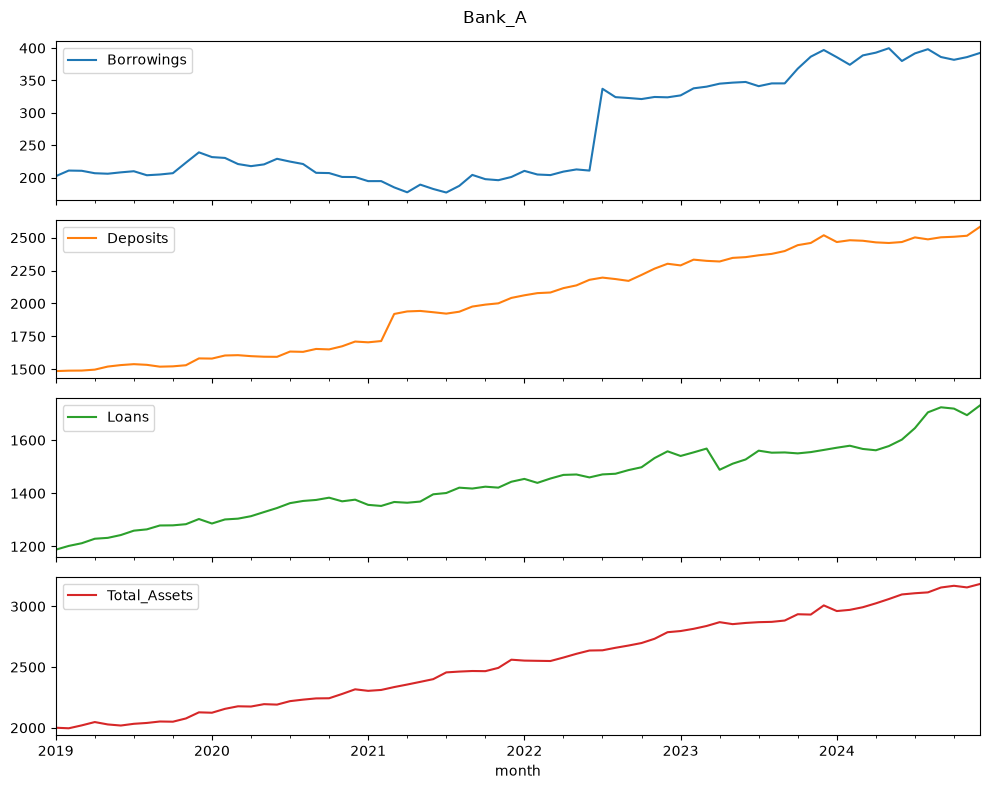

In [9]:
bank = "Bank_A"
wide[bank].plot(subplots=True, figsize=(10, 8), title=bank)
plt.tight_layout()
plt.show()

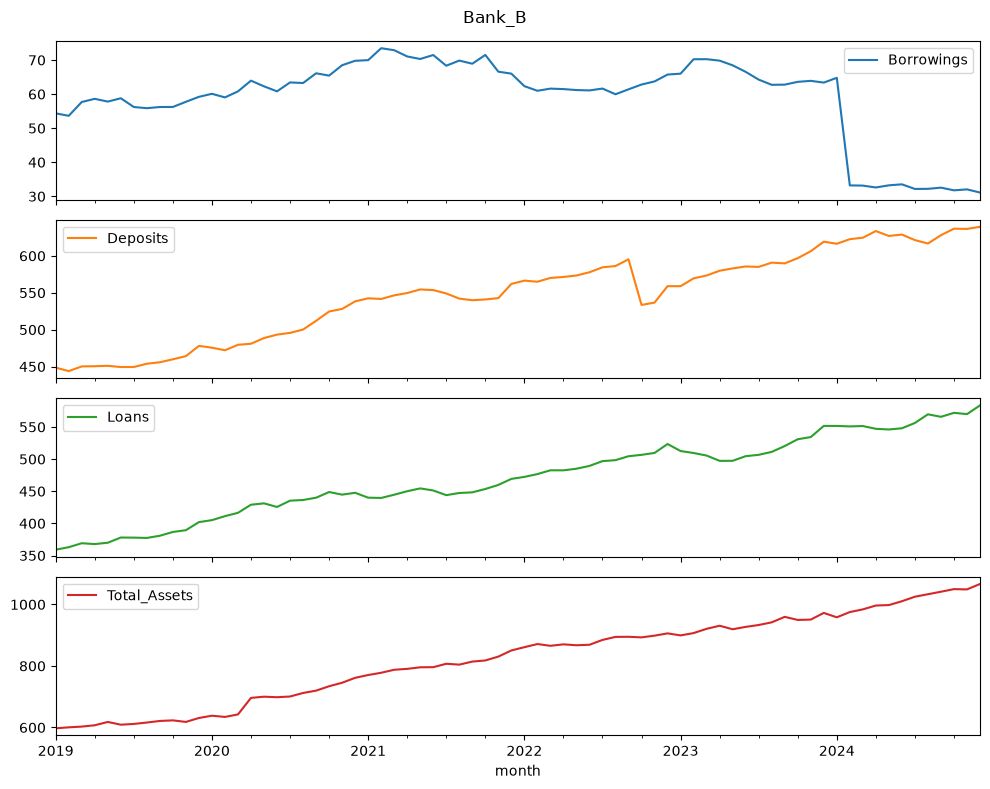

In [10]:
bank = "Bank_B"
wide[bank].plot(subplots=True, figsize=(10, 8), title=bank)
plt.tight_layout()
plt.show()

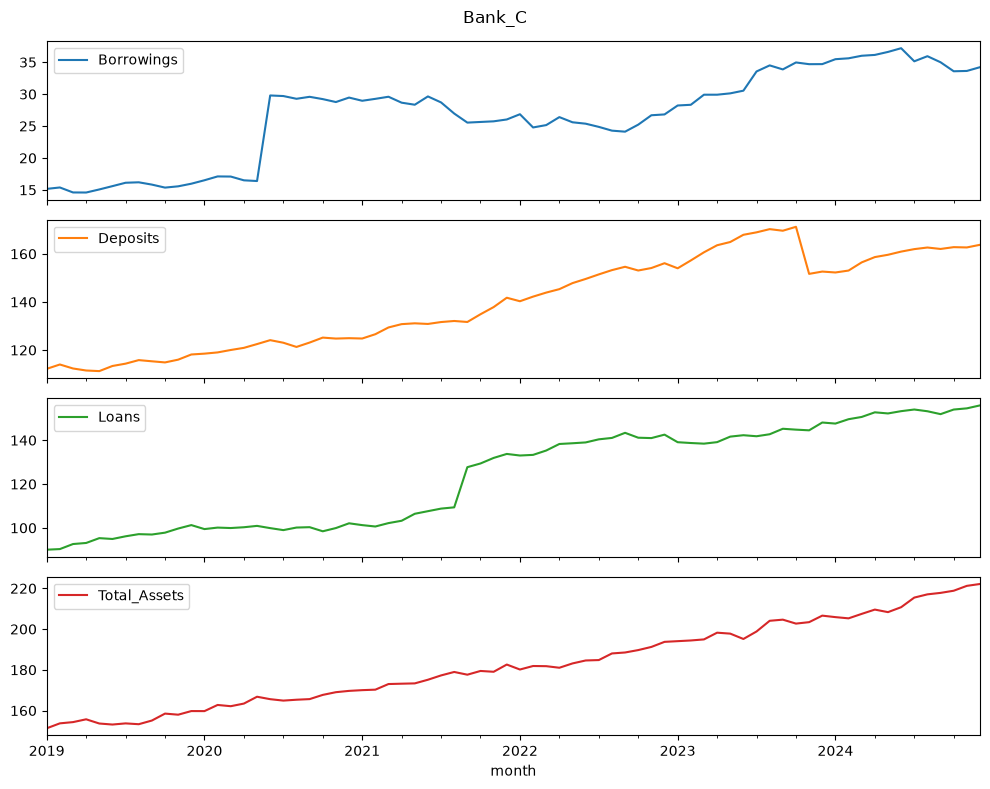

In [11]:
bank = "Bank_C"
wide[bank].plot(subplots=True, figsize=(10, 8), title=bank)
plt.tight_layout()
plt.show()

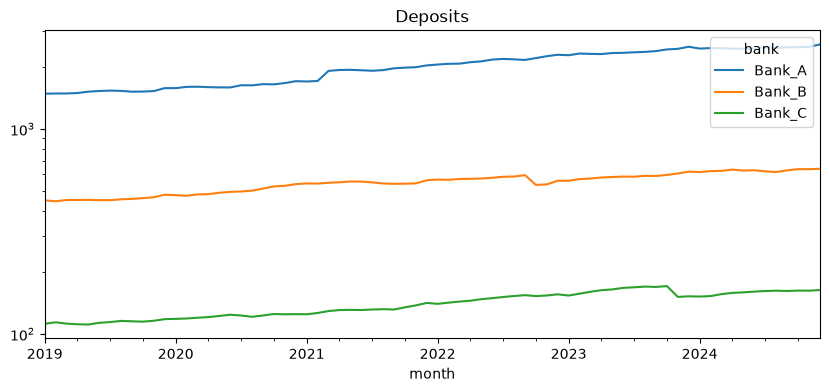

In [12]:
wide.xs("Deposits", axis=1, level="item").plot(logy=True, figsize=(10, 4), title="Deposits")
plt.show()

### Feature Engineering

In [13]:
pct = wide.pct_change().dropna()
pct.head()

bank           Bank_A                                      Bank_B            \
item       Borrowings  Deposits     Loans Total_Assets Borrowings  Deposits   
month                                                                         
2019-02-28   0.043119  0.002261  0.011972    -0.002324  -0.013245 -0.010478   
2019-03-31  -0.001659  0.000490  0.008419     0.012008   0.075690  0.014351   
2019-04-30  -0.017854  0.004731  0.013910     0.013523   0.015945  0.000555   
2019-05-31  -0.003723  0.015596  0.002726    -0.009612  -0.013818  0.001199   
2019-06-30   0.010288  0.007412  0.008585    -0.004414   0.016952 -0.003636   

bank                                  Bank_C                                   
item           Loans Total_Assets Borrowings  Deposits     Loans Total_Assets  
month                                                                          
2019-02-28  0.010833     0.005172   0.014512  0.016135  0.003109     0.015995  
2019-03-31  0.016998     0.003980  -0.050715 -0.014563  0.025459     0.003968  
2019-04-30 -0.003576     0.007215  -0.000685 -0.007478  0.005289     0.008942  
2019-05-31  0.005736     0.017769   0.032899 -0.002242  0.023623    -0.013294  
2019-06-30  0.021814    -0.014530   0.034506  0.019148 -0.003986    -0.003254

In [14]:
features_A = pct["Bank_A"]
features_A.head()

item,Borrowings,Deposits,Loans,Total_Assets
month,,,,
2019-02-28,0.043119,0.002261,0.011972,-0.002324
2019-03-31,-0.001659,0.000490,0.008419,0.012008
2019-04-30,-0.017854,0.004731,0.013910,0.013523
2019-05-31,-0.003723,0.015596,0.002726,-0.009612
2019-06-30,0.010288,0.007412,0.008585,-0.004414


### Creating the model

In [17]:
from sklearn.ensemble import IsolationForest

X = pct["Bank_A"]

model = IsolationForest(n_estimators=200, contamination=0.03, random_state=42)
model.fit(X)

result = X.copy()
result["label"] = model.predict(X)             # -1 = anomaly, 1 = normal
result["score"] = model.decision_function(X)   # lower = more abnormal

In [18]:
result[result["label"] == -1].sort_values("score")

item,Borrowings,Deposits,Loans,Total_Assets,label,score
month,,,,,,
2022-07-31,0.598398,0.007652,0.007720,0.000675,-1,-0.075448
2021-03-31,-0.049725,0.120119,0.010995,0.010256,-1,-0.060642
2023-04-30,0.013542,-0.002053,-0.050855,0.011049,-1,-0.000205


In [19]:
results = {}
for bank in pct.columns.get_level_values(0).unique():
    X = pct[bank]
    m = IsolationForest(n_estimators=200, contamination=0.03, random_state=42).fit(X)
    r = X.copy()
    r["label"] = m.predict(X)
    r["score"] = m.decision_function(X)
    results[bank] = r

### Evaluating the predictions

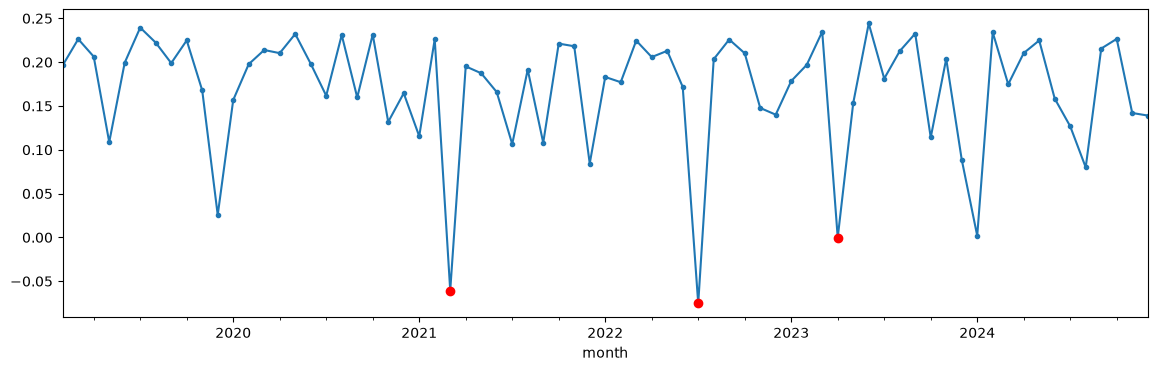

In [20]:
r = results["Bank_A"]
ax = r["score"].plot(figsize=(14, 4), marker="o", markersize=3)
ax.scatter(r.index[r["label"] == -1], r.loc[r["label"] == -1, "score"], color="red", zorder=3)
plt.show()

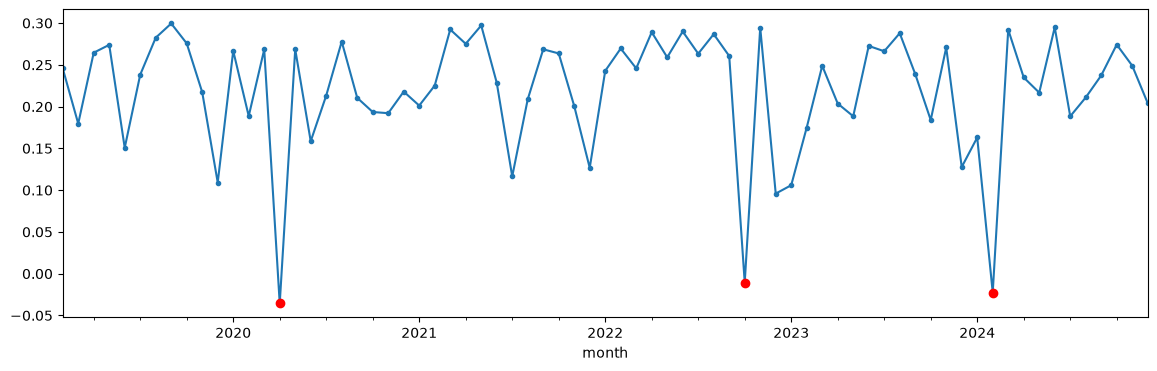

In [21]:
r = results["Bank_B"]
ax = r["score"].plot(figsize=(14, 4), marker="o", markersize=3)
ax.scatter(r.index[r["label"] == -1], r.loc[r["label"] == -1, "score"], color="red", zorder=3)
plt.show()

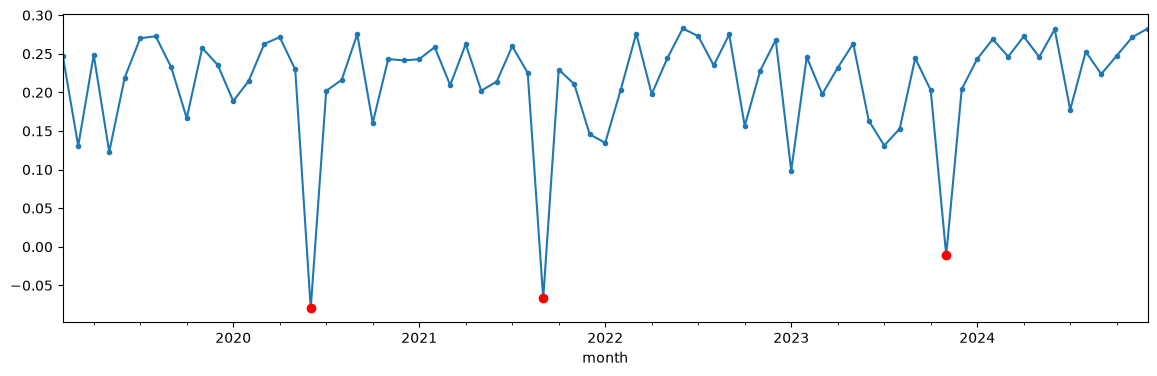

In [22]:
r = results["Bank_C"]
ax = r["score"].plot(figsize=(14, 4), marker="o", markersize=3)
ax.scatter(r.index[r["label"] == -1], r.loc[r["label"] == -1, "score"], color="red", zorder=3)
plt.show()